### 1. Mount Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 2. Settings 


In [ ]:
DATASET_SRC = "/content/drive/MyDrive/archive.zip" 
OUT         = "/content/drive/MyDrive/motor-claim-runs"
PARTS_RUN  = "parts_frcnn_640"
DAMAGE_RUN = "damage_maskrcnn_1024"

DAMAGE_MERGE = {"Cracked": "Other damage", "Flaking": "Other damage", "Corrosion": "Other damage"}

SEED = 42
import os
os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true") 
os.makedirs(OUT, exist_ok=True)
print("runs will be written under:", OUT)

runs will be written under: /content/drive/MyDrive/motor-claim-runs


In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
NVIDIA L4, 23034 MiB


In [ ]:
!pip install -q "torchmetrics>=1.4" "pycocotools>=2.0.7" "mlflow>=2.14"

### 3. Imports


In [ ]:
import json, random, shutil, time, zipfile
from collections import Counter
from dataclasses import dataclass
from pathlib import Path

import mlflow
import numpy as np
import torch
from PIL import Image, ImageDraw
from torch.utils.data import DataLoader, Dataset
from torchmetrics.detection import MeanAveragePrecision
from torchvision import tv_tensors
from torchvision.transforms import v2

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("torch", torch.__version__, "| device", DEVICE, "| amp", USE_AMP)

torch 2.14.1+cu130 | device cuda | amp True


### 4. Unpack the dataset and identify which folder is which

The folder named Car damages dataset actually contains car parts, and vice versa.
This cell ignores the folder names and reads the class list inside each `meta.json`.

In [ ]:
os.makedirs("/content/data", exist_ok=True)
if os.path.isdir(DATASET_SRC):
    shutil.copytree(DATASET_SRC, "/content/data/dataset", dirs_exist_ok=True)
else:
    with zipfile.ZipFile(DATASET_SRC) as z:
        z.extractall("/content/data")

# The two folders are named the wrong way round in the Kaggle download, so the roots
# are identified by the class names inside meta.json, never by the folder name.
DAMAGE_HINTS = {"Scratch", "Dent", "Broken part", "Missing part", "Paint chip"}
PART_HINTS   = {"Hood", "Front-bumper", "Headlight", "Roof", "Windshield"}

def classes_in(root):
    meta = json.loads((Path(root) / "meta.json").read_text(encoding="utf-8"))
    return [c["title"] for c in meta["classes"]]

ROOTS = {}
for meta_path in sorted(Path("/content/data").rglob("meta.json")):
    root = meta_path.parent
    if not (root / "File1" / "ann").is_dir():
        continue
    names = set(classes_in(root))
    kind = "damage" if names & DAMAGE_HINTS else ("parts" if names & PART_HINTS else None)
    if kind and kind not in ROOTS:
        ROOTS[kind] = root

assert set(ROOTS) == {"damage", "parts"}, f"could not identify both datasets: {ROOTS}"
DAMAGE_ROOT, PARTS_ROOT = ROOTS["damage"], ROOTS["parts"]
for kind, root in ROOTS.items():
    print(f"{kind:7s} <- {root.name}  ({len(classes_in(root))} classes: {', '.join(classes_in(root)[:4])}, ...)")

parts   <- Car damages dataset  (21 classes: Quarter-panel, Front-wheel, Back-window, Trunk, ...)
damage  <- Car parts dataset  (8 classes: Missing part, Broken part, Scratch, Cracked, ...)


### 5. Annotation parsing (polygons → boxes, and the polygons kept for masks)

In [ ]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
MIN_BOX_SIDE = 1.0 


class AnnotationFormatError(ValueError):
    """The files are not in the Supervisely layout this notebook expects."""


@dataclass
class Instance:
    label: str
    box: tuple    
    polygon: list 


@dataclass
class Annotation:
    width: int
    height: int
    instances: list
    skipped: int = 0


@dataclass
class Sample:
    image_path: Path
    annotation: Annotation


def class_list(root, merge=None):
    """Class titles in meta.json order, with any merge applied and duplicates removed."""
    merge = merge or {}
    out = []
    for title in classes_in(root):
        name = merge.get(title, title)
        if name not in out:
            out.append(name)
    return out


def polygon_to_box(exterior, width, height):
    xs = [p[0] for p in exterior]
    ys = [p[1] for p in exterior]
    x1, x2 = max(0.0, min(xs)), min(float(width), max(xs))
    y1, y2 = max(0.0, min(ys)), min(float(height), max(ys))
    if x2 - x1 < MIN_BOX_SIDE or y2 - y1 < MIN_BOX_SIDE:
        return None
    return (float(x1), float(y1), float(x2), float(y2))


def parse_annotation(data, known_classes=None, merge=None):
    merge = merge or {}
    try:
        width, height = int(data["size"]["width"]), int(data["size"]["height"])
        objects = data["objects"]
    except (KeyError, TypeError, ValueError) as e:
        raise AnnotationFormatError("annotation needs size {width,height} and an objects list") from e

    instances, skipped = [], 0
    for obj in objects:
        if obj.get("geometryType") != "polygon":
            skipped += 1
            continue
        try:
            label = merge.get(obj["classTitle"], obj["classTitle"])
            exterior = obj["points"]["exterior"]
        except (KeyError, TypeError) as e:
            raise AnnotationFormatError(f"malformed polygon object (id={obj.get('id')})") from e
        if known_classes is not None and label not in known_classes:
            raise AnnotationFormatError(f"class {label!r} is not in meta.json")
        box = polygon_to_box(exterior, width, height) if len(exterior) >= 3 else None
        if box is None:
            skipped += 1
            continue
        instances.append(Instance(label, box, [list(map(float, p)) for p in exterior]))
    return Annotation(width, height, instances, skipped)


def polygon_mask(polygon, sx, sy, width, height):
    """Rasterise one polygon to a uint8 mask at the real image size."""
    m = Image.new("L", (width, height), 0)
    ImageDraw.Draw(m).polygon([(p[0] * sx, p[1] * sy) for p in polygon], outline=1, fill=1)
    return np.asarray(m, dtype=np.uint8)

### 6. Scanning a dataset and splitting it 80/10/10

In [ ]:
def scan_dataset(root, classes, merge=None, subset="File1"):
    """Pair every annotation with its image. Fails loudly rather than training on nothing."""
    root = Path(root)
    img_dir, ann_dir = root / subset / "img", root / subset / "ann"
    for p in (root / "meta.json", img_dir, ann_dir):
        if not p.exists():
            raise AnnotationFormatError(f"expected path not found: {p}")

    images = [p for p in img_dir.iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS]
    by_name = {p.name: p for p in images}
    by_stem = {p.stem: p for p in images}
    known = set(classes)

    samples, missing, per_class = [], [], Counter()
    skipped = size_mismatch = empty = 0
    ann_files = sorted(ann_dir.glob("*.json"))
    for ann_path in ann_files:
        ann = parse_annotation(json.loads(ann_path.read_text(encoding="utf-8")), known, merge)
        name = ann_path.name[: -len(".json")]
        image = by_name.get(name) or by_stem.get(Path(name).stem)
        if image is None:
            missing.append(ann_path.name)
            continue
        with Image.open(image) as im:
            if im.size != (ann.width, ann.height):
                size_mismatch += 1   # boxes and polygons are rescaled when loaded
        skipped += ann.skipped
        empty += 0 if ann.instances else 1
        per_class.update(i.label for i in ann.instances)
        samples.append(Sample(image, ann))

    report = {"annotation_files": len(ann_files), "paired_with_image": len(samples),
              "annotations_without_image": len(missing), "first_unpaired": missing[:5],
              "skipped_objects": skipped, "images_without_objects": empty,
              "size_mismatch_images": size_mismatch, "instances_per_class": dict(per_class)}
    if not samples:
        raise AnnotationFormatError(f"nothing paired in {img_dir}. Report: {report}")
    return samples, report


def split_samples(samples, val_frac=0.1, test_frac=0.1, seed=SEED):
    """Reproducible split by image: (train, val, test)."""
    ordered = sorted(samples, key=lambda s: str(s.image_path))
    random.Random(seed).shuffle(ordered)
    n_val, n_test = round(len(ordered) * val_frac), round(len(ordered) * test_frac)
    if min(n_val, n_test, len(ordered) - n_val - n_test) < 1:
        raise ValueError(f"{len(ordered)} images are too few for this split")
    return ordered[n_val + n_test:], ordered[:n_val], ordered[n_val:n_val + n_test]

### 7. Dataset class and augmentation

In [ ]:
def make_transforms(train, with_masks):
    """Colour and flip augmentation. Scale jitter is handled by the model's own
    transform (a tuple of min_size values, sampled per step during training)."""
    steps = [v2.ToImage()]
    if train:
        steps += [
            v2.RandomHorizontalFlip(p=0.5),     
            v2.RandomPhotometricDistort(p=0.5), 
            v2.RandomZoomOut(fill=0, side_range=(1.0, 1.4), p=0.3),
        ]
    steps.append(v2.ToDtype(torch.float32, scale=True))
    if train:
        steps.append(v2.SanitizeBoundingBoxes()) 
    return v2.Compose(steps)


class DetectionDataset(Dataset):
    """(image, target) in torchvision detection format. Labels are 1..N; 0 is background."""

    def __init__(self, samples, classes, train=False, with_masks=False):
        self.samples = samples
        self.classes = classes
        self.label_to_idx = {name: i + 1 for i, name in enumerate(classes)}
        self.with_masks = with_masks
        self.tf = make_transforms(train, with_masks)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, i):
        s = self.samples[i]
        with Image.open(s.image_path) as im:
            image = im.convert("RGB")
        w, h = image.size
        ann = s.annotation
        sx, sy = w / ann.width, h / ann.height

        boxes = [[b[0] * sx, b[1] * sy, b[2] * sx, b[3] * sy] for b in (n.box for n in ann.instances)]
        labels = [self.label_to_idx[n.label] for n in ann.instances]

        target = {
            "boxes": tv_tensors.BoundingBoxes(
                torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
                format="XYXY", canvas_size=(h, w)),
            "labels": torch.tensor(labels, dtype=torch.int64),
            "image_id": torch.tensor([i]),
        }
        if self.with_masks:
            masks = [polygon_mask(n.polygon, sx, sy, w, h) for n in ann.instances]
            stacked = np.stack(masks) if masks else np.zeros((0, h, w), dtype=np.uint8)
            target["masks"] = tv_tensors.Mask(torch.from_numpy(stacked))

        image, target = self.tf(tv_tensors.Image(image), target)
        target["area"] = (target["boxes"][:, 2] - target["boxes"][:, 0]) * \
                         (target["boxes"][:, 3] - target["boxes"][:, 1])
        target["iscrowd"] = torch.zeros(len(target["labels"]), dtype=torch.int64)
        return image, target


def collate_fn(batch):
    return tuple(zip(*batch))

### 8. The two model builders

Both start from COCO-pretrained weights (transfer learning) and get a fresh classification head.

In [ ]:
from torchvision.models.detection import (
    FasterRCNN_MobileNet_V3_Large_FPN_Weights, MaskRCNN_ResNet50_FPN_V2_Weights,
    fasterrcnn_mobilenet_v3_large_fpn, maskrcnn_resnet50_fpn_v2,
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor


def build_faster_rcnn(num_classes, min_sizes, max_size, pretrained=True):
    """Boxes only. MobileNetV3 backbone: small enough to run on a 2 GB GPU or on CPU.

    min_sizes is a tuple: torchvision samples from it each training step (scale jitter)
    and uses the LAST value at eval time, so put the intended inference size last.
    """
    kwargs = {"min_size": tuple(min_sizes), "max_size": max_size}
    if pretrained:
        model = fasterrcnn_mobilenet_v3_large_fpn(
            weights=FasterRCNN_MobileNet_V3_Large_FPN_Weights.COCO_V1,
            trainable_backbone_layers=3, **kwargs)
    else:
        model = fasterrcnn_mobilenet_v3_large_fpn(weights=None, weights_backbone=None, **kwargs)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes + 1)
    return model


def build_mask_rcnn(num_classes, min_sizes, max_size, pretrained=True):
    """Boxes AND pixel masks. Damage is shapeless, so a box is a poor fit for it;
    the polygons in this dataset give masks for free. Heavier than the box model."""
    kwargs = {"min_size": tuple(min_sizes), "max_size": max_size}
    if pretrained:
        model = maskrcnn_resnet50_fpn_v2(
            weights=MaskRCNN_ResNet50_FPN_V2_Weights.COCO_V1,
            trainable_backbone_layers=3, **kwargs)
    else:
        model = maskrcnn_resnet50_fpn_v2(weights=None, weights_backbone=None, **kwargs)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes + 1)
    mask_in = model.roi_heads.mask_predictor.conv5_mask.in_channels
    model.roi_heads.mask_predictor = MaskRCNNPredictor(mask_in, 256, num_classes + 1)
    return model

### 9. Training loop, evaluation

In [ ]:
def save_atomic(obj, path):
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(obj, tmp)
    tmp.replace(path)      


@torch.no_grad()
def evaluate(model, loader, classes, with_masks, max_batches=0):
    model.eval()
    box_metric = MeanAveragePrecision(iou_type="bbox", class_metrics=True)
    seg_metric = MeanAveragePrecision(iou_type="segm", class_metrics=True) if with_masks else None

    for b, (images, targets) in enumerate(loader):
        if max_batches and b >= max_batches:
            break
        outputs = model([i.to(DEVICE) for i in images])
        preds = [{"boxes": o["boxes"].cpu(), "scores": o["scores"].cpu(), "labels": o["labels"].cpu()}
                 for o in outputs]
        gts = [{"boxes": t["boxes"].cpu(), "labels": t["labels"].cpu()} for t in targets]
        box_metric.update(preds, gts)
        if seg_metric is not None:
            for p, o in zip(preds, outputs):
                p["masks"] = (o["masks"].cpu() > 0.5).squeeze(1).to(torch.uint8)
            for g, t in zip(gts, targets):
                g["masks"] = t["masks"].cpu().to(torch.uint8)
            seg_metric.update(preds, gts)

    def unpack(metric, prefix):
        r = metric.compute()
        scores = {f"{prefix}{k}": float(r[k]) for k in ("map", "map_50", "map_75", "mar_100")}
        per_class = {classes[int(c) - 1]: float(v)
                     for c, v in zip(torch.atleast_1d(r["classes"]), torch.atleast_1d(r["map_per_class"]))}
        return scores, per_class

    scores, per_class = unpack(box_metric, "box_")
    seg_per_class = {}
    if seg_metric is not None:
        seg_scores, seg_per_class = unpack(seg_metric, "seg_")
        scores.update(seg_scores)
    return scores, {"box": per_class, "seg": seg_per_class}


def train_one_epoch(model, loader, optimizer, scaler, warmup, max_batches=0):
    model.train()
    total = n = 0
    for b, (images, targets) in enumerate(loader):
        if max_batches and b >= max_batches:
            break
        images = [i.to(DEVICE) for i in images]
        targets = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets]
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            loss_dict = model(images, targets)
            loss = sum(loss_dict.values())
        if not torch.isfinite(loss):
            raise RuntimeError(f"non-finite loss at batch {b}: "
                               f"{ {k: float(v) for k, v in loss_dict.items()} }")
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update()
        if warmup is not None:
            warmup.step()
        total += float(loss.detach()); n += 1
    return total / max(n, 1)


def run_training(name, root, *, with_masks, min_sizes, max_size, merge=None, epochs=20,
                 batch_size=8, lr=0.005, weight_decay=5e-4, num_workers=2,
                 select_on="box_map_50", max_batches=0, out_root=None):
    """Train one detector. Saves last.pt every epoch and always resumes from it,
    so a Colab disconnect costs at most one epoch. Returns the metrics dict."""
    out = Path(out_root or OUT) / name
    out.mkdir(parents=True, exist_ok=True)
    set_seed()

    classes = class_list(root, merge)
    samples, report = scan_dataset(root, classes, merge)
    print("dataset report:", json.dumps(report, indent=2))
    train_s, val_s, test_s = split_samples(samples)
    print(f"split: train={len(train_s)} val={len(val_s)} test={len(test_s)}")
    (out / "splits.json").write_text(json.dumps(
        {"seed": SEED, **{k: [s.image_path.name for s in v]
                          for k, v in (("train", train_s), ("val", val_s), ("test", test_s))}}, indent=1))

    def loader(ss, train):
        return DataLoader(DetectionDataset(ss, classes, train=train, with_masks=with_masks),
                          batch_size=batch_size, shuffle=train, num_workers=num_workers,
                          collate_fn=collate_fn, pin_memory=USE_AMP, persistent_workers=num_workers > 0)

    train_loader, val_loader, test_loader = loader(train_s, True), loader(val_s, False), loader(test_s, False)

    build = build_mask_rcnn if with_masks else build_faster_rcnn
    model = build(len(classes), min_sizes, max_size).to(DEVICE)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    last_path, best_path = out / "last.pt", out / "best.pt"
    start_epoch, best_score, run_id = 0, -1.0, None
    if last_path.exists():
        ck = torch.load(last_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
        scheduler.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"])
        start_epoch, best_score, run_id = ck["epoch"] + 1, ck["best_score"], ck["mlflow_run_id"]
        print(f"resuming {name} from epoch {start_epoch}")

    mlflow.set_tracking_uri((Path(out_root or OUT) / "mlruns").resolve().as_uri())
    mlflow.set_experiment("car-claims-vision")
    with mlflow.start_run(run_id=run_id, run_name=name) as run:
        if run_id is None:
            mlflow.log_params({"name": name, "dataset": Path(root).name, "with_masks": with_masks,
                               "min_sizes": str(min_sizes), "max_size": max_size, "epochs": epochs,
                               "batch_size": batch_size, "lr": lr, "weight_decay": weight_decay,
                               "merge": json.dumps(merge or {}), "classes": len(classes),
                               "train_images": len(train_s), "augmentation": "hflip+photometric+zoomout"})

        for epoch in range(start_epoch, epochs):
            t0 = time.time()
            warmup = None
            if epoch == 0:
                warmup = torch.optim.lr_scheduler.LinearLR(
                    optimizer, start_factor=1e-3, total_iters=max(1, min(500, len(train_loader) - 1)))
            loss = train_one_epoch(model, train_loader, optimizer, scaler, warmup, max_batches)
            scheduler.step()
            scores, _ = evaluate(model, val_loader, classes, with_masks, max_batches)
            mlflow.log_metrics({"train_loss": loss, **{f"val_{k}": v for k, v in scores.items()}}, step=epoch)
            shown = " ".join(f"{k}={v:.4f}" for k, v in scores.items() if k.endswith(("map", "map_50")))
            print(f"[{name}] epoch {epoch + 1}/{epochs} loss={loss:.4f} {shown} ({time.time() - t0:.0f}s)")

            if scores[select_on] > best_score or not best_path.exists():
                best_score = max(best_score, scores[select_on])
                save_atomic({"model": model.state_dict(), "classes": classes, "with_masks": with_masks,
                             "min_sizes": tuple(min_sizes), "max_size": max_size,
                             "val_metrics": scores, "epoch": epoch}, best_path)
            save_atomic({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                         "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                         "epoch": epoch, "best_score": best_score,
                         "mlflow_run_id": run.info.run_id}, last_path)

        best = torch.load(best_path, map_location=DEVICE, weights_only=True)
        model.load_state_dict(best["model"])
        test_scores, per_class = evaluate(model, test_loader, classes, with_masks, max_batches)
        mlflow.log_metrics({f"test_{k}": v for k, v in test_scores.items()})
        metrics = {"name": name, "classes": classes, "with_masks": with_masks,
                   "split_sizes": [len(train_s), len(val_s), len(test_s)], "best_epoch": best["epoch"],
                   "selected_on": select_on, "val": best["val_metrics"], "test": test_scores,
                   "test_ap_per_class": per_class, "dataset_report": report,
                   "config": {"min_sizes": list(min_sizes), "max_size": max_size, "lr": lr,
                              "batch_size": batch_size, "epochs": epochs, "merge": merge or {}}}
        (out / "metrics.json").write_text(json.dumps(metrics, indent=1))
        mlflow.log_artifact(str(out / "metrics.json")); mlflow.log_artifact(str(out / "splits.json"))
        print("test:", json.dumps(test_scores, indent=1))
    return metrics

In [ ]:
_ = run_training("smoke_parts", PARTS_ROOT, with_masks=False, min_sizes=(512, 640),
                 max_size=1024, epochs=1, batch_size=4, max_batches=2, out_root="/content/smoke")
_ = run_training("smoke_damage", DAMAGE_ROOT, with_masks=True, min_sizes=(640, 800),
                 max_size=1333, merge=DAMAGE_MERGE, epochs=1, batch_size=2, max_batches=2,
                 select_on="seg_map_50", out_root="/content/smoke")
print("\nsmoke test passed")

dataset report: {
  "annotation_files": 998,
  "paired_with_image": 998,
  "annotations_without_image": 0,
  "first_unpaired": [],
  "skipped_objects": 0,
  "images_without_objects": 0,
  "size_mismatch_images": 0,
  "instances_per_class": {
    "Back-bumper": 443,
    "Back-door": 721,
    "Back-wheel": 865,
    "Back-window": 1237,
    "Back-windshield": 271,
    "Fender": 935,
    "Front-bumper": 705,
    "Front-door": 917,
    "Front-wheel": 885,
    "Front-window": 951,
    "Headlight": 914,
    "Hood": 712,
    "Mirror": 987,
    "Quarter-panel": 855,
    "Rocker-panel": 860,
    "Roof": 793,
    "Tail-light": 721,
    "Trunk": 416,
    "Windshield": 632,
    "Grille": 577,
    "License-plate": 370
  }
}
split: train=798 val=100 test=100
Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth


100%|██████████| 74.2M/74.2M [00:00<00:00, 160MB/s]
2026/11/13 16:06:34 INFO mlflow.tracking.fluent: Experiment with name 'car-claims-vision' does not exist. Creating a new experiment.
/tmp/ipykernel_455/3154350226.py:61: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warmup.step()


[smoke_parts] epoch 1/1 loss=4.9873 box_map=0.0008 box_map_50=0.0080 (11s)
test: {
 "box_map": 0.0002877726801671088,
 "box_map_50": 0.0006146433297544718,
 "box_map_75": 0.0,
 "box_mar_100": 0.0034391535446047783
}
dataset report: {
  "annotation_files": 814,
  "paired_with_image": 814,
  "annotations_without_image": 0,
  "first_unpaired": [],
  "skipped_objects": 2,
  "images_without_objects": 0,
  "size_mismatch_images": 0,
  "instances_per_class": {
    "Broken part": 1500,
    "Scratch": 3240,
    "Dent": 1664,
    "Other damage": 690,
    "Paint chip": 1356,
    "Missing part": 632
  }
}
split: train=652 val=81 test=81
Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth


100%|██████████| 177M/177M [00:00<00:00, 235MB/s]


[smoke_damage] epoch 1/1 loss=8.2247 box_map=0.0000 box_map_50=0.0000 seg_map=0.0000 seg_map_50=0.0000 (2s)
test: {
 "box_map": 0.0,
 "box_map_50": 0.0,
 "box_map_75": 0.0,
 "box_mar_100": 0.0,
 "seg_map": 0.0,
 "seg_map_50": 0.0,
 "seg_map_75": 0.0,
 "seg_mar_100": 0.0
}

smoke test passed


### 10. Parts detector 

Faster R-CNN / MobileNetV3. Last run scored **0.83 box mAP@50**, so only scale jitter and
colour augmentation are added. About 22 s/epoch on an L4.

In [ ]:
parts_metrics = run_training(
    PARTS_RUN, PARTS_ROOT,
    with_masks=False,
    min_sizes=(512, 576, 608, 640),   # scale jitter while training; 640 is used at eval
    max_size=1024,
    epochs=20, batch_size=8, lr=0.005,
)

dataset report: {
  "annotation_files": 998,
  "paired_with_image": 998,
  "annotations_without_image": 0,
  "first_unpaired": [],
  "skipped_objects": 0,
  "images_without_objects": 0,
  "size_mismatch_images": 0,
  "instances_per_class": {
    "Back-bumper": 443,
    "Back-door": 721,
    "Back-wheel": 865,
    "Back-window": 1237,
    "Back-windshield": 271,
    "Fender": 935,
    "Front-bumper": 705,
    "Front-door": 917,
    "Front-wheel": 885,
    "Front-window": 951,
    "Headlight": 914,
    "Hood": 712,
    "Mirror": 987,
    "Quarter-panel": 855,
    "Rocker-panel": 860,
    "Roof": 793,
    "Tail-light": 721,
    "Trunk": 416,
    "Windshield": 632,
    "Grille": 577,
    "License-plate": 370
  }
}
split: train=798 val=100 test=100
resuming parts_frcnn_640 from epoch 20
test: {
 "box_map": 0.5386285185813904,
 "box_map_50": 0.8360125422477722,
 "box_map_75": 0.594790518283844,
 "box_mar_100": 0.612334132194519
}


### 11. Damage detector

Mask R-CNN / ResNet-50 at a larger input size. This scored only 0.068 before.

In [ ]:
damage_metrics = run_training(
    DAMAGE_RUN, DAMAGE_ROOT,
    with_masks=True,             
    merge=DAMAGE_MERGE,       
    min_sizes=(800, 896, 1024),  
    max_size=1333,
    epochs=20, batch_size=4,
    lr=0.0025, weight_decay=1e-4,  
    select_on="seg_map_50",    
)

dataset report: {
  "annotation_files": 814,
  "paired_with_image": 814,
  "annotations_without_image": 0,
  "first_unpaired": [],
  "skipped_objects": 2,
  "images_without_objects": 0,
  "size_mismatch_images": 0,
  "instances_per_class": {
    "Broken part": 1500,
    "Scratch": 3240,
    "Dent": 1664,
    "Other damage": 690,
    "Paint chip": 1356,
    "Missing part": 632
  }
}
split: train=652 val=81 test=81
resuming damage_maskrcnn_1024 from epoch 20
test: {
 "box_map": 0.07095535844564438,
 "box_map_50": 0.14843814074993134,
 "box_map_75": 0.05833881348371506,
 "box_mar_100": 0.22623789310455322,
 "seg_map": 0.05953297019004822,
 "seg_map_50": 0.1348477602005005,
 "seg_map_75": 0.04916967451572418,
 "seg_mar_100": 0.18672797083854675
}


### 12. Results

In [ ]:
for run in (PARTS_RUN, DAMAGE_RUN):
    path = Path(OUT) / run / "metrics.json"
    if not path.exists():
        print(f"{run}: not run yet"); continue
    m = json.loads(path.read_text())
    print(f"\n=== {run}  (best epoch {m['best_epoch'] + 1}, {m['split_sizes']} images) ===")
    print("test:", {k: round(v, 3) for k, v in m["test"].items()})
    for kind, per_class in m["test_ap_per_class"].items():
        if per_class:
            ranked = sorted(per_class.items(), key=lambda kv: kv[1])
            print(f"  {kind} AP, worst first:", {k: round(v, 3) for k, v in ranked})


=== parts_frcnn_640  (best epoch 18, [798, 100, 100] images) ===
test: {'box_map': 0.539, 'box_map_50': 0.836, 'box_map_75': 0.595, 'box_mar_100': 0.612}
  box AP, worst first: {'Roof': 0.316, 'Mirror': 0.33, 'Quarter-panel': 0.363, 'Tail-light': 0.373, 'Trunk': 0.374, 'License-plate': 0.399, 'Back-bumper': 0.461, 'Grille': 0.492, 'Back-window': 0.52, 'Headlight': 0.53, 'Fender': 0.534, 'Front-window': 0.548, 'Rocker-panel': 0.56, 'Front-bumper': 0.607, 'Back-windshield': 0.628, 'Hood': 0.637, 'Back-wheel': 0.66, 'Back-door': 0.71, 'Front-wheel': 0.738, 'Front-door': 0.738, 'Windshield': 0.793}

=== damage_maskrcnn_1024  (best epoch 7, [652, 81, 81] images) ===
test: {'box_map': 0.071, 'box_map_50': 0.148, 'box_map_75': 0.058, 'box_mar_100': 0.226, 'seg_map': 0.06, 'seg_map_50': 0.135, 'seg_map_75': 0.049, 'seg_mar_100': 0.187}
  box AP, worst first: {'Other damage': 0.001, 'Paint chip': 0.01, 'Scratch': 0.026, 'Dent': 0.054, 'Broken part': 0.131, 'Missing part': 0.204}
  seg AP, wors

In [ ]:
from collections import defaultdict
import matplotlib.pyplot as plt

REPORT_DIR = f"{OUT}/evaluation" 
IOU_MATCH  = 0.5               
os.makedirs(REPORT_DIR, exist_ok=True)


def test_set(root, run_name):
    """Rebuild the exact TEST split of a finished run  """
    meta = json.loads((Path(OUT) / run_name / "metrics.json").read_text())
    classes, merge = meta["classes"], meta["config"]["merge"] or None
    wanted = set(json.loads((Path(OUT) / run_name / "splits.json").read_text())["test"])

    samples, _ = scan_dataset(root, classes, merge)
    test = [s for s in samples if s.image_path.name in wanted]
    assert len(test) == len(wanted), f"found {len(test)} of {len(wanted)} test images"

    ds = DetectionDataset(test, classes, train=False, with_masks=False)
    targets = [ds[i][1] for i in range(len(ds))]          # boxes already scaled to the image
    paths = [s.image_path for s in test]
    print(f"{run_name}: {len(test)} test images, {len(classes)} classes")
    return classes, paths, targets


DAMAGE_CLASSES, damage_paths, damage_gt = test_set(DAMAGE_ROOT, DAMAGE_RUN)
PARTS_CLASSES,  parts_paths,  parts_gt  = test_set(PARTS_ROOT,  PARTS_RUN)

damage_maskrcnn_1024: 81 test images, 6 classes
parts_frcnn_640: 100 test images, 21 classes


In [ ]:
from torchvision.transforms import functional as TF


def load_detector(run_name):
    """Rebuild the architecture recorded in best.pt and load its weights."""
    ck = torch.load(Path(OUT) / run_name / "best.pt", map_location="cpu", weights_only=True)
    build = build_mask_rcnn if ck["with_masks"] else build_faster_rcnn
    model = build(len(ck["classes"]), ck["min_sizes"], ck["max_size"], pretrained=False)
    model.load_state_dict(ck["model"])
    model.to(DEVICE).eval()
    print(f"{run_name}: {len(ck['classes'])} classes, masks={ck['with_masks']}, "
          f"best epoch {ck['epoch'] + 1}")
    return model


@torch.no_grad()
def predict_all(model, paths, score_floor=0.05):
    """One pass over the test set. The low floor lets the score threshold be swept
    afterwards without re-running inference."""
    out = []
    for p in paths:
        with Image.open(p) as im:
            t = TF.to_tensor(im.convert("RGB")).to(DEVICE)
        o = model([t])[0]
        k = o["scores"] >= score_floor
        out.append({"boxes": o["boxes"][k].cpu(), "scores": o["scores"][k].cpu(),
                    "labels": o["labels"][k].cpu()})
    return out


damage_model = load_detector(DAMAGE_RUN)
parts_model  = load_detector(PARTS_RUN)
damage_pred = predict_all(damage_model, damage_paths)
parts_pred  = predict_all(parts_model,  parts_paths)
print("inference done")

damage_maskrcnn_1024: 6 classes, masks=True, best epoch 7
parts_frcnn_640: 21 classes, masks=False, best epoch 18
inference done


In [ ]:
def box_iou(a, b):
    """IoU of every box in a against every box in b -> (len(a), len(b))."""
    if len(a) == 0 or len(b) == 0:
        return torch.zeros(len(a), len(b))
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    lt = torch.max(a[:, None, :2], b[None, :, :2])
    rb = torch.min(a[:, None, 2:], b[None, :, 2:])
    inter = (rb - lt).clamp(min=0).prod(2)
    return inter / (area_a[:, None] + area_b[None, :] - inter)


def aware_vs_agnostic(gt, pred):
    """Two mAP@50 numbers from the SAME predictions: once with the class labels,
    once with every object relabelled to a single class. The gap is exactly what
    getting the damage TYPE wrong costs us."""
    ap, ag, bp, bg = [], [], [], []
    for g, p in zip(gt, pred):
        ap.append({"boxes": p["boxes"], "scores": p["scores"], "labels": p["labels"]})
        ag.append({"boxes": g["boxes"], "labels": g["labels"]})
        bp.append({"boxes": p["boxes"], "scores": p["scores"], "labels": torch.ones_like(p["labels"])})
        bg.append({"boxes": g["boxes"], "labels": torch.ones_like(g["labels"])})

    def m50(p, g):
        m = MeanAveragePrecision(iou_type="bbox"); m.update(p, g)
        return float(m.compute()["map_50"])

    return m50(ap, ag), m50(bp, bg)


print("mAP@50 — what the class labels cost us\n")
for name, gt, pred in (("damage", damage_gt, damage_pred), ("parts", parts_gt, parts_pred)):
    aware, blind = aware_vs_agnostic(gt, pred)
    print(f"  {name:7s} with classes {aware:.3f}    class-agnostic {blind:.3f}    "
          f"gain from ignoring the label {blind - aware:+.3f}")

mAP@50 — what the class labels cost us

  damage  with classes 0.149    class-agnostic 0.184    gain from ignoring the label +0.035
  parts   with classes 0.830    class-agnostic 0.850    gain from ignoring the label +0.020


In [ ]:
def per_image_rates(gt, pred, thresholds=(0.3, 0.4, 0.5, 0.6, 0.7, 0.8)):
    """The question the claim pipeline actually asks, which mAP does not answer:
    on a photo that HAS damage, did the model notice, point at the right spot,
    and name the right kind?

      reported     - produced any detection at all
      located      - a detection overlapping a real object (IoU >= IOU_MATCH)
      right type   - that overlapping detection also carried the correct class
      false alarms - detections matching nothing, averaged per image
    """
    rows = []
    for t in thresholds:
        n = reported = located = typed = fp = 0
        for g, p in zip(gt, pred):
            if len(g["boxes"]) == 0:
                continue
            n += 1
            k = p["scores"] >= t
            pb, pl = p["boxes"][k], p["labels"][k]
            reported += len(pb) > 0
            if len(pb) == 0:
                continue
            iou = box_iou(pb, g["boxes"])
            best_iou, best_j = iou.max(dim=1)
            ok = best_iou >= IOU_MATCH
            located += bool(ok.any())
            typed += bool((ok & (pl == g["labels"][best_j])).any())
            fp += int((~ok).sum())
        rows.append({"threshold": t, "reported": reported / n, "located": located / n,
                     "right type": typed / n, "false alarms": fp / n})
    return rows


def show_rates(rows, title):
    cols = ["threshold", "reported", "located", "right type", "false alarms"]
    print(f"\n{title}")
    print("  " + "".join(f"{c:>14s}" for c in cols))
    for r in rows:
        print("  " + "".join(f"{r[c]:>14.2f}" for c in cols))


damage_rows = per_image_rates(damage_gt, damage_pred)
parts_rows  = per_image_rates(parts_gt,  parts_pred)
show_rates(damage_rows, f"DAMAGE — {len(damage_gt)} held-out images")
show_rates(parts_rows,  f"PARTS  — {len(parts_gt)} held-out images")
json.dump({"damage": damage_rows, "parts": parts_rows},
          open(f"{REPORT_DIR}/per_image_rates.json", "w"), indent=1)
print(f"\nsaved -> {REPORT_DIR}/per_image_rates.json")


DAMAGE — 81 held-out images
       threshold      reported       located    right type  false alarms
            0.30          1.00          0.98          0.94         16.90
            0.40          1.00          0.98          0.93         10.41
            0.50          0.99          0.96          0.90          6.17
            0.60          0.98          0.84          0.79          3.58
            0.70          0.93          0.74          0.67          1.91
            0.80          0.75          0.59          0.54          0.70

PARTS  — 100 held-out images
       threshold      reported       located    right type  false alarms
            0.30          1.00          1.00          1.00          2.54
            0.40          1.00          1.00          1.00          1.91
            0.50          1.00          1.00          1.00          1.49
            0.60          1.00          1.00          1.00          1.04
            0.70          1.00          1.00          1.00       

In [ ]:
def confusion(gt, pred, classes, score_thr=0.5):
    """For every ground-truth object: what did the model call it, or did it miss it?
    Rows are the truth, columns the prediction, with a final '(missed)' column."""
    mat = np.zeros((len(classes), len(classes) + 1), dtype=int)
    for g, p in zip(gt, pred):
        if len(g["boxes"]) == 0:
            continue
        k = p["scores"] >= score_thr
        pb, pl = p["boxes"][k], p["labels"][k]
        iou = box_iou(pb, g["boxes"])
        for j, true_label in enumerate(g["labels"].tolist()):
            col = len(classes)                                  # missed, unless matched below
            if iou.numel():
                cand = iou[:, j]
                if float(cand.max()) >= IOU_MATCH:
                    col = int(pl[int(cand.argmax())]) - 1
            mat[true_label - 1, col] += 1
    return mat


def show_confusion(mat, classes, title):
    cols = classes + ["(missed)"]
    w = 13
    print(f"\n{title}  — rows = truth, columns = what the model said (score 0.5)\n")
    print(" " * 16 + "".join(f"{c[:11]:>{w}}" for c in cols) + f"{'recall':>9}")
    for i, cls in enumerate(classes):
        total, hit = mat[i].sum(), mat[i, i]
        print(f"{cls:<16}" + "".join(f"{v:>{w}}" for v in mat[i]) +
              f"{(hit / total if total else 0):>9.2f}")


dmat = confusion(damage_gt, damage_pred, DAMAGE_CLASSES)
show_confusion(dmat, DAMAGE_CLASSES, "DAMAGE")
np.savetxt(f"{REPORT_DIR}/damage_confusion.csv", dmat, fmt="%d", delimiter=",",
           header=",".join(DAMAGE_CLASSES + ["(missed)"]))


DAMAGE  — rows = truth, columns = what the model said (score 0.5)

                  Missing par  Broken part      Scratch  Other damag         Dent   Paint chip     (missed)   recall
Missing part               29            1            0            0            0            0           29     0.49
Broken part                 4           58            1            0            9            0          103     0.33
Scratch                     0            0           41            0            4            1          228     0.15
Other damage                3            0            3            0            1            0           45     0.00
Dent                        1            5            2            0           37            0           95     0.26
Paint chip                  0            0            4            0            0            3           70     0.04


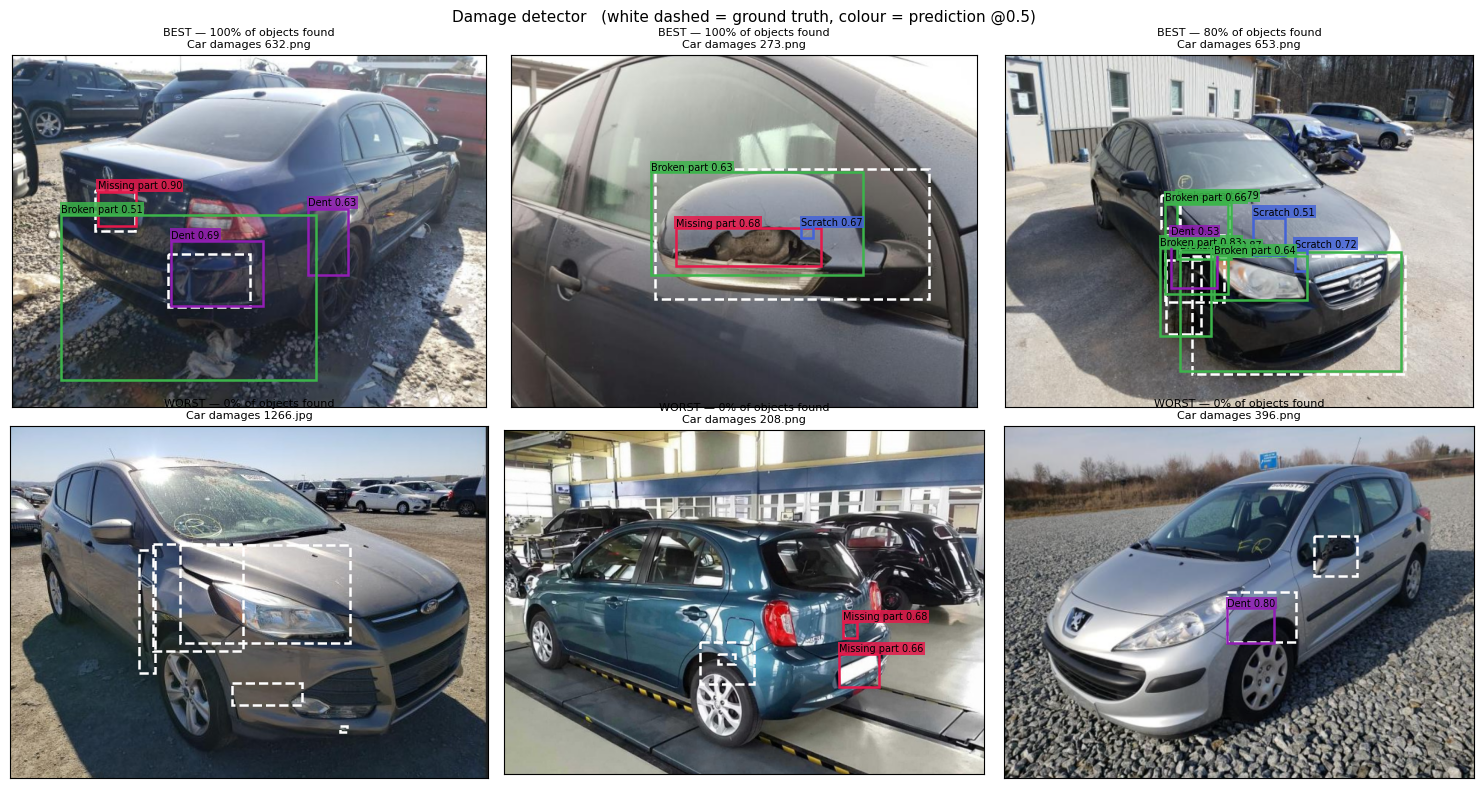

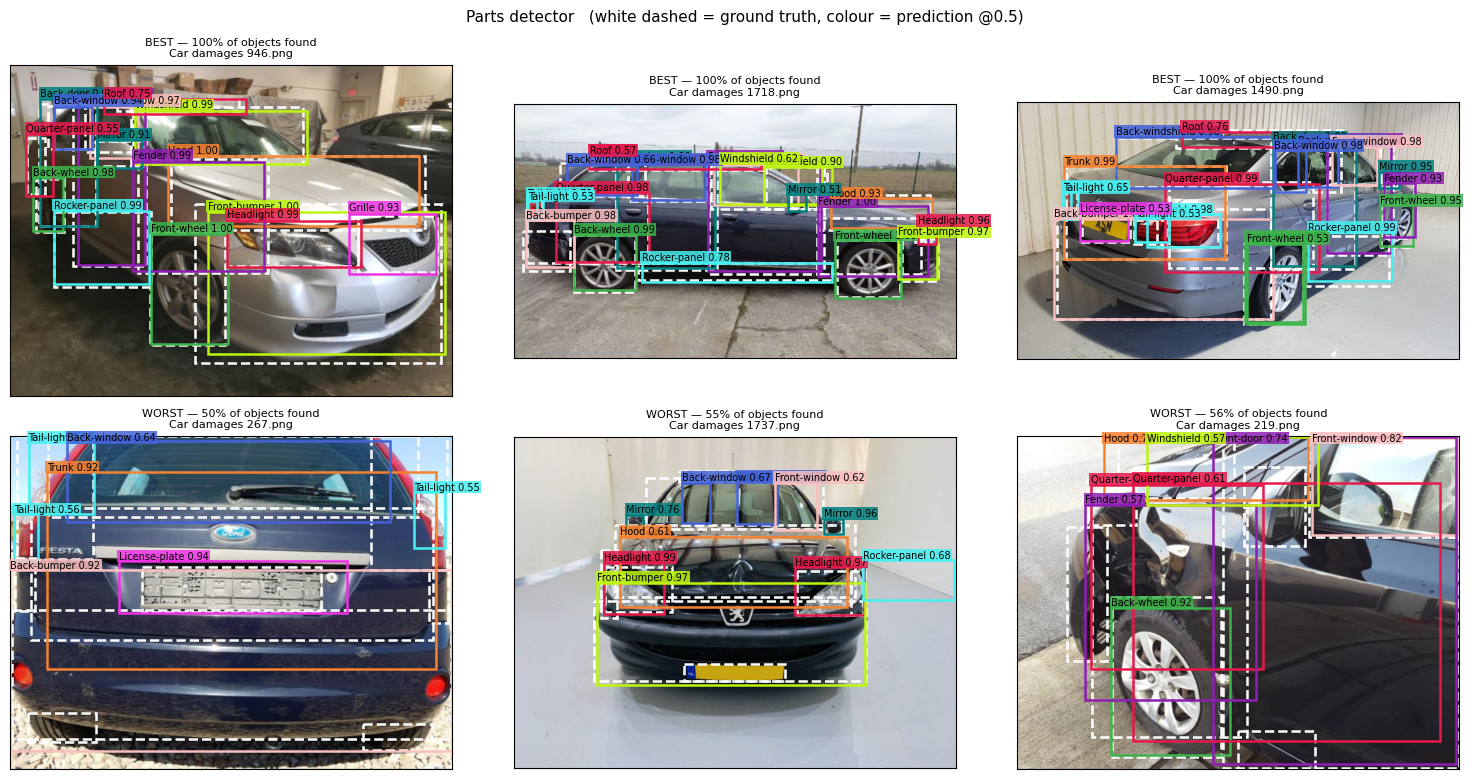

figures saved to /content/drive/MyDrive/motor-claim-runs/evaluation


In [ ]:
PALETTE = ["#e6194b", "#3cb44b", "#4363d8", "#f58231", "#911eb4",
           "#46f0f0", "#f032e6", "#bcf60c", "#fabebe", "#008080"]


def draw(ax, path, g, p, classes, score_thr=0.5):
    with Image.open(path) as im:
        ax.imshow(im.convert("RGB"))
    for b in g["boxes"].tolist():                               # truth: white dashed
        ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1],
                                   fill=False, ec="white", lw=1.8, ls="--"))
    k = p["scores"] >= score_thr
    for b, l, s in zip(p["boxes"][k].tolist(), p["labels"][k].tolist(), p["scores"][k].tolist()):
        c = PALETTE[(l - 1) % len(PALETTE)]
        ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec=c, lw=1.8))
        ax.text(b[0], max(b[1] - 4, 8), f"{classes[l - 1]} {s:.2f}", color="k", fontsize=7,
                bbox=dict(fc=c, ec="none", alpha=.85, pad=1))
    ax.set_xticks([]); ax.set_yticks([])


def found_fraction(g, p, score_thr=0.5):
    """Fraction of ground-truth objects matched — used to rank best vs worst images."""
    if len(g["boxes"]) == 0:
        return 1.0
    k = p["scores"] >= score_thr
    pb = p["boxes"][k]
    if len(pb) == 0:
        return 0.0
    return float((box_iou(pb, g["boxes"]).max(dim=0).values >= IOU_MATCH).float().mean())


def gallery(paths, gt, pred, classes, title, fname, n=6):
    ranked = sorted(range(len(gt)), key=lambda i: found_fraction(gt[i], pred[i]))
    picks = ranked[-(n // 2):][::-1] + ranked[:n // 2]
    tags = ["BEST"] * (n // 2) + ["WORST"] * (n // 2)
    fig, axes = plt.subplots(2, n // 2, figsize=(5 * (n // 2), 8))
    for ax, i, tag in zip(axes.ravel(), picks, tags):
        draw(ax, paths[i], gt[i], pred[i], classes)
        ax.set_title(f"{tag} — {found_fraction(gt[i], pred[i]):.0%} of objects found\n"
                     f"{paths[i].name}", fontsize=8)
    fig.suptitle(f"{title}   (white dashed = ground truth, colour = prediction @0.5)", fontsize=11)
    fig.tight_layout()
    fig.savefig(f"{REPORT_DIR}/{fname}", dpi=110, bbox_inches="tight")
    plt.show()


gallery(damage_paths, damage_gt, damage_pred, DAMAGE_CLASSES, "Damage detector", "damage_examples.png")
gallery(parts_paths,  parts_gt,  parts_pred,  PARTS_CLASSES,  "Parts detector",  "parts_examples.png")
print("figures saved to", REPORT_DIR)

In [ ]:
def containment(d, p):
    """Fraction of damage box d lying inside part box p."""
    area = (d[2] - d[0]) * (d[3] - d[1])
    if area <= 0:
        return 0.0
    inter = (max(0.0, min(d[2], p[2]) - max(d[0], p[0])) *
             max(0.0, min(d[3], p[3]) - max(d[1], p[1])))
    return inter / area


@torch.no_grad()
def assess(image_path, score_thr=0.5, min_containment=0.5):
    """Both detectors on one photo, each damage assigned to the part containing most
    of it. This dict is what the claim pipeline consumes.

    No image in this dataset carries BOTH part and damage labels, so this cannot be
    scored here - it is a demonstration, and the hand-labelled claims will test it.
    """
    with Image.open(image_path) as im:
        t = TF.to_tensor(im.convert("RGB")).to(DEVICE)
    dmg, prt = damage_model([t])[0], parts_model([t])[0]

    parts = [(PARTS_CLASSES[int(l) - 1], b.tolist()) for b, l, s
             in zip(prt["boxes"], prt["labels"], prt["scores"]) if s >= score_thr]
    dmgs = [(DAMAGE_CLASSES[int(l) - 1], b.tolist()) for b, l, s
            in zip(dmg["boxes"], dmg["labels"], dmg["scores"]) if s >= score_thr]

    found, unlinked = defaultdict(set), []
    for dname, dbox in dmgs:
        best, best_c = None, 0.0
        for pname, pbox in parts:
            c = containment(dbox, pbox)
            if c >= min_containment and c > best_c:
                best, best_c = pname, c
        found[best].add(dname) if best else unlinked.append(dname)

    return {"parts_detected": sorted({p[0] for p in parts}),
            "damaged_parts": {k: sorted(v) for k, v in sorted(found.items())},
            "damage_not_linked_to_a_part": sorted(unlinked),
            "needs_manual_review": not parts or bool(unlinked)}


for p in damage_paths[:3]:
    print(p.name)
    print(json.dumps(assess(p), indent=2), "\n")

Car damages 106.png
{
  "parts_detected": [
    "Fender",
    "Front-bumper",
    "Front-door",
    "Front-wheel",
    "Grille",
    "Headlight",
    "Hood",
    "Rocker-panel"
  ],
  "damaged_parts": {
    "Fender": [
      "Broken part",
      "Dent"
    ],
    "Front-bumper": [
      "Broken part",
      "Scratch"
    ],
    "Hood": [
      "Broken part"
    ]
  },
  "damage_not_linked_to_a_part": [],
  "needs_manual_review": false
} 

Car damages 1063.png
{
  "parts_detected": [
    "Back-door",
    "Back-wheel",
    "Back-window",
    "Fender",
    "Front-bumper",
    "Front-door",
    "Front-wheel",
    "Front-window",
    "Grille",
    "Headlight",
    "Hood",
    "Mirror",
    "Rocker-panel",
    "Roof",
    "Windshield"
  ],
  "damaged_parts": {
    "Front-bumper": [
      "Missing part",
      "Scratch"
    ],
    "Grille": [
      "Missing part"
    ]
  },
  "damage_not_linked_to_a_part": [],
  "needs_manual_review": false
} 

Car damages 1065.png
{
  "parts_detected": [
   

In [ ]:
from torchvision.models.detection import (
    FasterRCNN_ResNet50_FPN_V2_Weights, fasterrcnn_resnet50_fpn_v2)


def build_faster_rcnn_r50(num_classes, min_sizes, max_size, pretrained=True):
    """Faster R-CNN with the ResNet-50 backbone: the Mask R-CNN run's backbone without
    the mask head, so backbone and architecture are no longer confounded."""
    kw = {"min_size": tuple(min_sizes), "max_size": max_size}
    if pretrained:
        m = fasterrcnn_resnet50_fpn_v2(weights=FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1,
                                       trainable_backbone_layers=3, **kw)
    else:
        m = fasterrcnn_resnet50_fpn_v2(weights=None, weights_backbone=None, **kw)
    m.roi_heads.box_predictor = FastRCNNPredictor(
        m.roi_heads.box_predictor.cls_score.in_features, num_classes + 1)
    return m


_original_build_faster_rcnn = build_faster_rcnn

GRID = [
    # run name          backbone builder             min_sizes         max   batch
    ("abl_mnv3_640",   _original_build_faster_rcnn, (512, 576, 640),  1024, 8),
    ("abl_mnv3_1024",  _original_build_faster_rcnn, (800, 896, 1024), 1333, 8),
    ("abl_r50_640",    build_faster_rcnn_r50,       (512, 576, 640),  1024, 8),
    ("abl_r50_1024",   build_faster_rcnn_r50,       (800, 896, 1024), 1333, 4),
]

try:
    for _name, _builder, _min_sizes, _max_size, _bs in GRID:
        build_faster_rcnn = _builder        # deliberate swap, restored in `finally`
        run_training(_name, DAMAGE_ROOT, with_masks=False, merge=DAMAGE_MERGE,
                     min_sizes=_min_sizes, max_size=_max_size, epochs=20,
                     batch_size=_bs, lr=0.0025, weight_decay=1e-4,
                     select_on="box_map_50")
finally:
    build_faster_rcnn = _original_build_faster_rcnn

print()
print("  backbone / input size      box mAP@50   best epoch")
for _name, *_rest in GRID:
    _m = json.loads((Path(OUT) / _name / "metrics.json").read_text())
    print(f"  {_name:24s} {_m['test']['box_map_50']:>9.3f} {_m['best_epoch'] + 1:>12}")
print("  (for reference, Mask R-CNN / ResNet-50 @1024 scored 0.148)")

dataset report: {
  "annotation_files": 814,
  "paired_with_image": 814,
  "annotations_without_image": 0,
  "first_unpaired": [],
  "skipped_objects": 2,
  "images_without_objects": 0,
  "size_mismatch_images": 0,
  "instances_per_class": {
    "Broken part": 1500,
    "Scratch": 3240,
    "Dent": 1664,
    "Other damage": 690,
    "Paint chip": 1356,
    "Missing part": 632
  }
}
split: train=652 val=81 test=81


/tmp/ipykernel_455/3154350226.py:61: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warmup.step()


[abl_mnv3_640] epoch 1/20 loss=1.2724 box_map=0.0054 box_map_50=0.0187 (31s)
[abl_mnv3_640] epoch 2/20 loss=0.9330 box_map=0.0235 box_map_50=0.0639 (22s)
[abl_mnv3_640] epoch 3/20 loss=0.8960 box_map=0.0339 box_map_50=0.0927 (20s)
[abl_mnv3_640] epoch 4/20 loss=0.8627 box_map=0.0407 box_map_50=0.1037 (20s)
[abl_mnv3_640] epoch 5/20 loss=0.8347 box_map=0.0479 box_map_50=0.1202 (20s)
[abl_mnv3_640] epoch 6/20 loss=0.8233 box_map=0.0553 box_map_50=0.1309 (21s)
[abl_mnv3_640] epoch 7/20 loss=0.8134 box_map=0.0560 box_map_50=0.1338 (20s)
[abl_mnv3_640] epoch 8/20 loss=0.8009 box_map=0.0627 box_map_50=0.1476 (19s)
[abl_mnv3_640] epoch 9/20 loss=0.8012 box_map=0.0622 box_map_50=0.1402 (19s)
[abl_mnv3_640] epoch 10/20 loss=0.7837 box_map=0.0647 box_map_50=0.1485 (19s)
[abl_mnv3_640] epoch 11/20 loss=0.7714 box_map=0.0671 box_map_50=0.1535 (21s)
[abl_mnv3_640] epoch 12/20 loss=0.7681 box_map=0.0672 box_map_50=0.1537 (18s)
[abl_mnv3_640] epoch 13/20 loss=0.7500 box_map=0.0693 box_map_50=0.1530 (

100%|██████████| 167M/167M [00:00<00:00, 243MB/s]


[abl_r50_640] epoch 1/20 loss=2.1850 box_map=0.0114 box_map_50=0.0340 (50s)
[abl_r50_640] epoch 2/20 loss=1.3639 box_map=0.0392 box_map_50=0.0990 (49s)
[abl_r50_640] epoch 3/20 loss=1.2766 box_map=0.0578 box_map_50=0.1300 (50s)
[abl_r50_640] epoch 4/20 loss=1.2231 box_map=0.0691 box_map_50=0.1492 (50s)
[abl_r50_640] epoch 5/20 loss=1.1803 box_map=0.0698 box_map_50=0.1526 (50s)
[abl_r50_640] epoch 6/20 loss=1.1517 box_map=0.0774 box_map_50=0.1660 (49s)
[abl_r50_640] epoch 7/20 loss=1.1179 box_map=0.0767 box_map_50=0.1654 (49s)
[abl_r50_640] epoch 8/20 loss=1.0916 box_map=0.0855 box_map_50=0.1748 (49s)
[abl_r50_640] epoch 9/20 loss=1.0673 box_map=0.0864 box_map_50=0.1831 (49s)
[abl_r50_640] epoch 10/20 loss=1.0434 box_map=0.0859 box_map_50=0.1792 (50s)
[abl_r50_640] epoch 11/20 loss=1.0267 box_map=0.0883 box_map_50=0.1853 (49s)
[abl_r50_640] epoch 12/20 loss=1.0233 box_map=0.0919 box_map_50=0.1842 (49s)
[abl_r50_640] epoch 13/20 loss=1.0019 box_map=0.0893 box_map_50=0.1856 (49s)
[abl_r50

In [ ]:
from torchvision.models.detection import (
    FasterRCNN_ResNet50_FPN_V2_Weights, fasterrcnn_resnet50_fpn_v2)


def build_faster_rcnn_r50(num_classes, min_sizes, max_size, pretrained=True):
    """Faster R-CNN with the ResNet-50 backbone: the Mask R-CNN run's backbone without
    the mask head, so backbone and architecture are no longer confounded."""
    kw = {"min_size": tuple(min_sizes), "max_size": max_size}
    if pretrained:
        m = fasterrcnn_resnet50_fpn_v2(weights=FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1,
                                       trainable_backbone_layers=3, **kw)
    else:
        m = fasterrcnn_resnet50_fpn_v2(weights=None, weights_backbone=None, **kw)
    m.roi_heads.box_predictor = FastRCNNPredictor(
        m.roi_heads.box_predictor.cls_score.in_features, num_classes + 1)
    return m


_original_build_faster_rcnn = build_faster_rcnn

GRID = [
    # run name          backbone builder             min_sizes         max   batch
    ("abl_mnv3_640",   _original_build_faster_rcnn, (512, 576, 640),  1024, 8),
    ("abl_mnv3_1024",  _original_build_faster_rcnn, (800, 896, 1024), 1333, 8),
    ("abl_r50_640",    build_faster_rcnn_r50,       (512, 576, 640),  1024, 8),
    ("abl_r50_1024",   build_faster_rcnn_r50,       (800, 896, 1024), 1333, 4),
]

try:
    for _name, _builder, _min_sizes, _max_size, _bs in GRID:
        build_faster_rcnn = _builder        # deliberate swap, restored in `finally`
        run_training(_name, DAMAGE_ROOT, with_masks=False, merge=DAMAGE_MERGE,
                     min_sizes=_min_sizes, max_size=_max_size, epochs=20,
                     batch_size=_bs, lr=0.0025, weight_decay=1e-4,
                     select_on="box_map_50")
finally:
    build_faster_rcnn = _original_build_faster_rcnn

print()
print("  backbone / input size      box mAP@50   best epoch")
for _name, *_rest in GRID:
    _m = json.loads((Path(OUT) / _name / "metrics.json").read_text())
    print(f"  {_name:24s} {_m['test']['box_map_50']:>9.3f} {_m['best_epoch'] + 1:>12}")
print("  (for reference, Mask R-CNN / ResNet-50 @1024 scored 0.148)")

dataset report: {
  "annotation_files": 814,
  "paired_with_image": 814,
  "annotations_without_image": 0,
  "first_unpaired": [],
  "skipped_objects": 2,
  "images_without_objects": 0,
  "size_mismatch_images": 0,
  "instances_per_class": {
    "Broken part": 1500,
    "Scratch": 3240,
    "Dent": 1664,
    "Other damage": 690,
    "Paint chip": 1356,
    "Missing part": 632
  }
}
split: train=652 val=81 test=81
resuming abl_mnv3_640 from epoch 20
test: {
 "box_map": 0.03314448520541191,
 "box_map_50": 0.07887424528598785,
 "box_map_75": 0.022936265915632248,
 "box_mar_100": 0.12647512555122375
}
dataset report: {
  "annotation_files": 814,
  "paired_with_image": 814,
  "annotations_without_image": 0,
  "first_unpaired": [],
  "skipped_objects": 2,
  "images_without_objects": 0,
  "size_mismatch_images": 0,
  "instances_per_class": {
    "Broken part": 1500,
    "Scratch": 3240,
    "Dent": 1664,
    "Other damage": 690,
    "Paint chip": 1356,
    "Missing part": 632
  }
}
split: tra

In [ ]:
FINAL_DAMAGE_RUN = "final_r50_640_40ep"

_orig = build_faster_rcnn
try:
    build_faster_rcnn = build_faster_rcnn_r50     # defined in the ablation cell above
    run_training(FINAL_DAMAGE_RUN, DAMAGE_ROOT, with_masks=False, merge=DAMAGE_MERGE,
                 min_sizes=(512, 576, 640), max_size=1024, epochs=40, batch_size=8,
                 lr=0.0025, weight_decay=1e-4, select_on="box_map_50")
finally:
    build_faster_rcnn = _orig

_m = json.loads((Path(OUT) / FINAL_DAMAGE_RUN / "metrics.json").read_text())
print(f"\n40 epochs: box mAP@50 {_m['test']['box_map_50']:.3f}  (best epoch {_m['best_epoch'] + 1})")
print(f"20 epochs: box mAP@50 0.133  <- abl_r50_640")
print("If the best epoch is again at the very end, it is still undertrained.")

dataset report: {
  "annotation_files": 814,
  "paired_with_image": 814,
  "annotations_without_image": 0,
  "first_unpaired": [],
  "skipped_objects": 2,
  "images_without_objects": 0,
  "size_mismatch_images": 0,
  "instances_per_class": {
    "Broken part": 1500,
    "Scratch": 3240,
    "Dent": 1664,
    "Other damage": 690,
    "Paint chip": 1356,
    "Missing part": 632
  }
}
split: train=652 val=81 test=81


/tmp/ipykernel_455/3154350226.py:61: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warmup.step()


[final_r50_640_40ep] epoch 1/40 loss=2.1901 box_map=0.0121 box_map_50=0.0375 (50s)
[final_r50_640_40ep] epoch 2/40 loss=1.3595 box_map=0.0389 box_map_50=0.0993 (50s)
[final_r50_640_40ep] epoch 3/40 loss=1.2784 box_map=0.0559 box_map_50=0.1262 (49s)
[final_r50_640_40ep] epoch 4/40 loss=1.2226 box_map=0.0713 box_map_50=0.1492 (50s)
[final_r50_640_40ep] epoch 5/40 loss=1.1781 box_map=0.0742 box_map_50=0.1561 (50s)
[final_r50_640_40ep] epoch 6/40 loss=1.1492 box_map=0.0803 box_map_50=0.1718 (49s)
[final_r50_640_40ep] epoch 7/40 loss=1.1213 box_map=0.0818 box_map_50=0.1660 (49s)
[final_r50_640_40ep] epoch 8/40 loss=1.0845 box_map=0.0899 box_map_50=0.1872 (49s)
[final_r50_640_40ep] epoch 9/40 loss=1.0643 box_map=0.0835 box_map_50=0.1792 (49s)
[final_r50_640_40ep] epoch 10/40 loss=1.0402 box_map=0.0863 box_map_50=0.1868 (49s)
[final_r50_640_40ep] epoch 11/40 loss=1.0179 box_map=0.0916 box_map_50=0.1841 (49s)
[final_r50_640_40ep] epoch 12/40 loss=1.0101 box_map=0.0914 box_map_50=0.1835 (49s)
[

In [ ]:
def load_detector(run_name, box_builder=None):
    """Rebuild the architecture recorded in best.pt and load its weights.
    box_builder: pass build_faster_rcnn_r50 for the ResNet-50 runs."""
    ck = torch.load(Path(OUT) / run_name / "best.pt", map_location="cpu", weights_only=True)
    build = build_mask_rcnn if ck["with_masks"] else (box_builder or build_faster_rcnn)
    model = build(len(ck["classes"]), ck["min_sizes"], ck["max_size"], pretrained=False)
    model.load_state_dict(ck["model"])
    model.to(DEVICE).eval()
    print(f"{run_name}: {len(ck['classes'])} classes, masks={ck['with_masks']}, "
          f"best epoch {ck['epoch'] + 1}")
    return model


DAMAGE_RUN = FINAL_DAMAGE_RUN
DAMAGE_CLASSES, damage_paths, damage_gt = test_set(DAMAGE_ROOT, DAMAGE_RUN)
damage_model = load_detector(DAMAGE_RUN, box_builder=build_faster_rcnn_r50)
parts_model  = load_detector(PARTS_RUN)
damage_pred = predict_all(damage_model, damage_paths)
parts_pred  = predict_all(parts_model,  parts_paths)
print("inference done on the final model")

final_r50_640_40ep: 81 test images, 6 classes
final_r50_640_40ep: 6 classes, masks=False, best epoch 13
parts_frcnn_640: 21 classes, masks=False, best epoch 18
inference done on the final model


In [ ]:
CANDIDATES = ["abl_r50_640",          # mAP@50 0.133, 640px, lighter
              "abl_r50_1024",         # mAP@50 0.150, 1024px, best mAP
              "final_r50_640_40ep"]   # mAP@50 0.130, 40 epochs - no gain

_names = {p.name for p in damage_paths}
bench = {}
for _run in CANDIDATES:
    _split = set(json.loads((Path(OUT) / _run / "splits.json").read_text())["test"])
    assert _split == _names, f"{_run} was tested on a different split"
    _model = load_detector(_run, box_builder=build_faster_rcnn_r50)
    _pred = predict_all(_model, damage_paths)
    bench[_run] = per_image_rates(damage_gt, _pred, thresholds=(0.5, 0.6, 0.7))
    del _model, _pred
    torch.cuda.empty_cache()

print(f"\n{'model':22s}{'thr':>6}{'located':>10}{'right type':>13}{'false alarms':>15}")
for _run, _rows in bench.items():
    for _r in _rows:
        print(f"{_run:22s}{_r['threshold']:>6.1f}{_r['located']:>10.2f}"
              f"{_r['right type']:>13.2f}{_r['false alarms']:>15.2f}")
    print()

json.dump(bench, open(f"{OUT}/evaluation/model_choice.json", "w"), indent=1)
print("Pick the best 'located' at an acceptable false-alarm rate.")
print("Differences under ~0.05 are noise on 81 images.")

abl_r50_640: 6 classes, masks=False, best epoch 20
abl_r50_1024: 6 classes, masks=False, best epoch 9
final_r50_640_40ep: 6 classes, masks=False, best epoch 13

model                    thr   located   right type   false alarms
abl_r50_640              0.5      0.83         0.80           6.64
abl_r50_640              0.6      0.80         0.78           4.25
abl_r50_640              0.7      0.74         0.70           2.48

abl_r50_1024             0.5      0.89         0.83           4.94
abl_r50_1024             0.6      0.84         0.80           3.25
abl_r50_1024             0.7      0.77         0.73           1.83

final_r50_640_40ep       0.5      0.88         0.88           7.72
final_r50_640_40ep       0.6      0.86         0.86           5.01
final_r50_640_40ep       0.7      0.81         0.79           3.15

Pick the best 'located' at an acceptable false-alarm rate.
Differences under ~0.05 are noise on 81 images.


In [ ]:
print(f"Damage model in use: {DAMAGE_RUN}\n")

for _name, _gt, _pred in (("damage", damage_gt, damage_pred), ("parts", parts_gt, parts_pred)):
    _aware, _blind = aware_vs_agnostic(_gt, _pred)
    print(f"  {_name:7s} mAP@50 with classes {_aware:.3f}   class-agnostic {_blind:.3f}   "
          f"{_blind - _aware:+.3f}")

damage_rows = per_image_rates(damage_gt, damage_pred)
parts_rows  = per_image_rates(parts_gt,  parts_pred)
show_rates(damage_rows, f"DAMAGE — {len(damage_gt)} held-out images")
show_rates(parts_rows,  f"PARTS  — {len(parts_gt)} held-out images")
json.dump({"model": DAMAGE_RUN, "damage": damage_rows, "parts": parts_rows},
          open(f"{REPORT_DIR}/per_image_rates.json", "w"), indent=1)

dmat = confusion(damage_gt, damage_pred, DAMAGE_CLASSES, score_thr=0.6)
show_confusion(dmat, DAMAGE_CLASSES, "DAMAGE @0.6")
np.savetxt(f"{REPORT_DIR}/damage_confusion.csv", dmat, fmt="%d", delimiter=",",
           header=",".join(DAMAGE_CLASSES + ["(missed)"]))

_tot, _missed = dmat.sum(), dmat[:, -1].sum()
_correct = np.trace(dmat[:, :-1])
print(f"\nAcross all {_tot} damage objects: {_missed/_tot:.0%} missed, "
      f"{_correct/_tot:.0%} found and named correctly, "
      f"{_correct/(_tot-_missed):.0%} of those found were named correctly.")
print(f"saved -> {REPORT_DIR}/")

Damage model in use: final_r50_640_40ep

  damage  mAP@50 with classes 0.130   class-agnostic 0.164   +0.033
  parts   mAP@50 with classes 0.830   class-agnostic 0.850   +0.020

DAMAGE — 81 held-out images
       threshold      reported       located    right type  false alarms
            0.30          1.00          0.95          0.93         15.86
            0.40          1.00          0.91          0.89         10.99
            0.50          1.00          0.88          0.88          7.72
            0.60          0.99          0.86          0.86          5.01
            0.70          0.98          0.81          0.79          3.15
            0.80          0.91          0.70          0.67          1.77

PARTS  — 100 held-out images
       threshold      reported       located    right type  false alarms
            0.30          1.00          1.00          1.00          2.54
            0.40          1.00          1.00          1.00          1.91
            0.50          1.00    

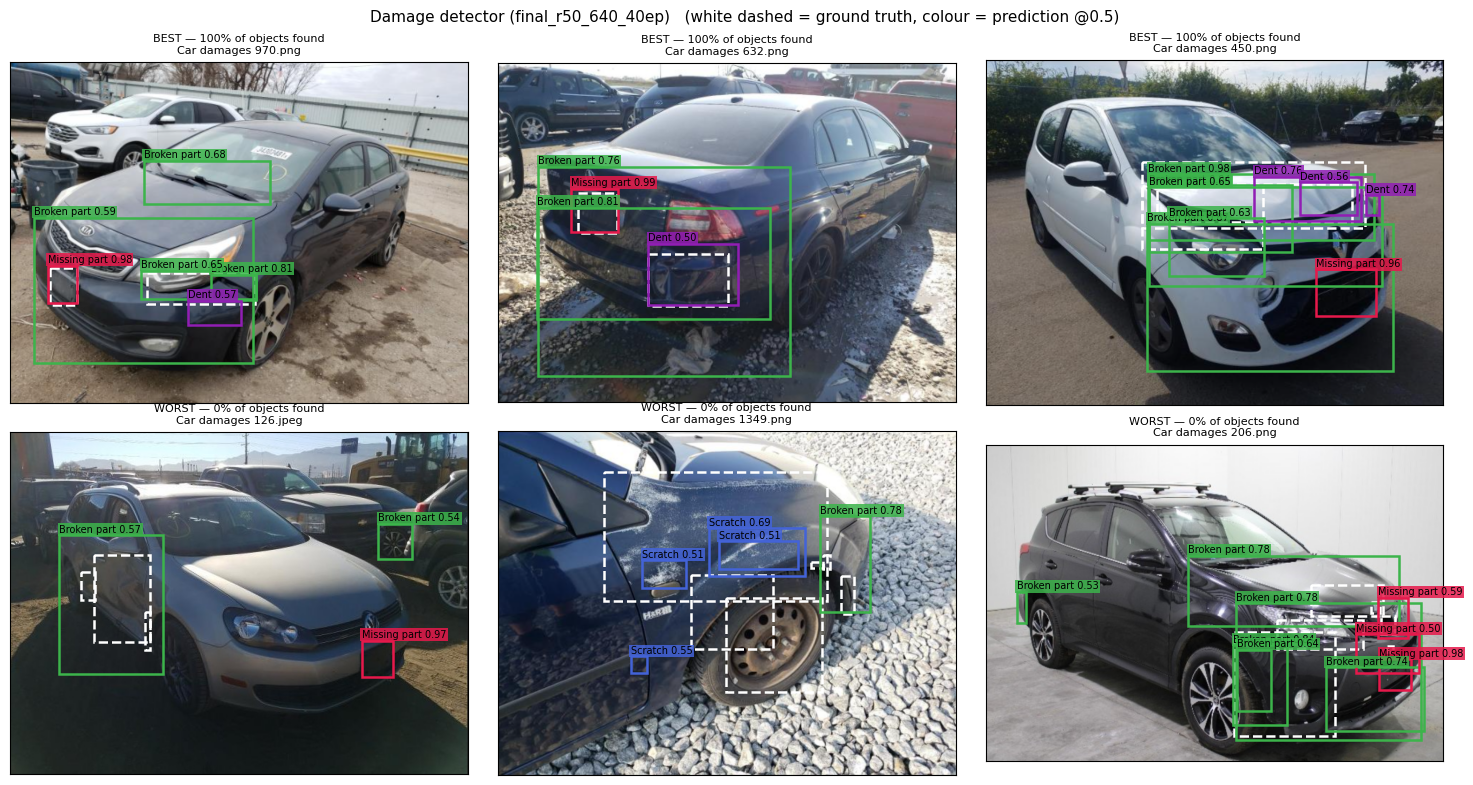

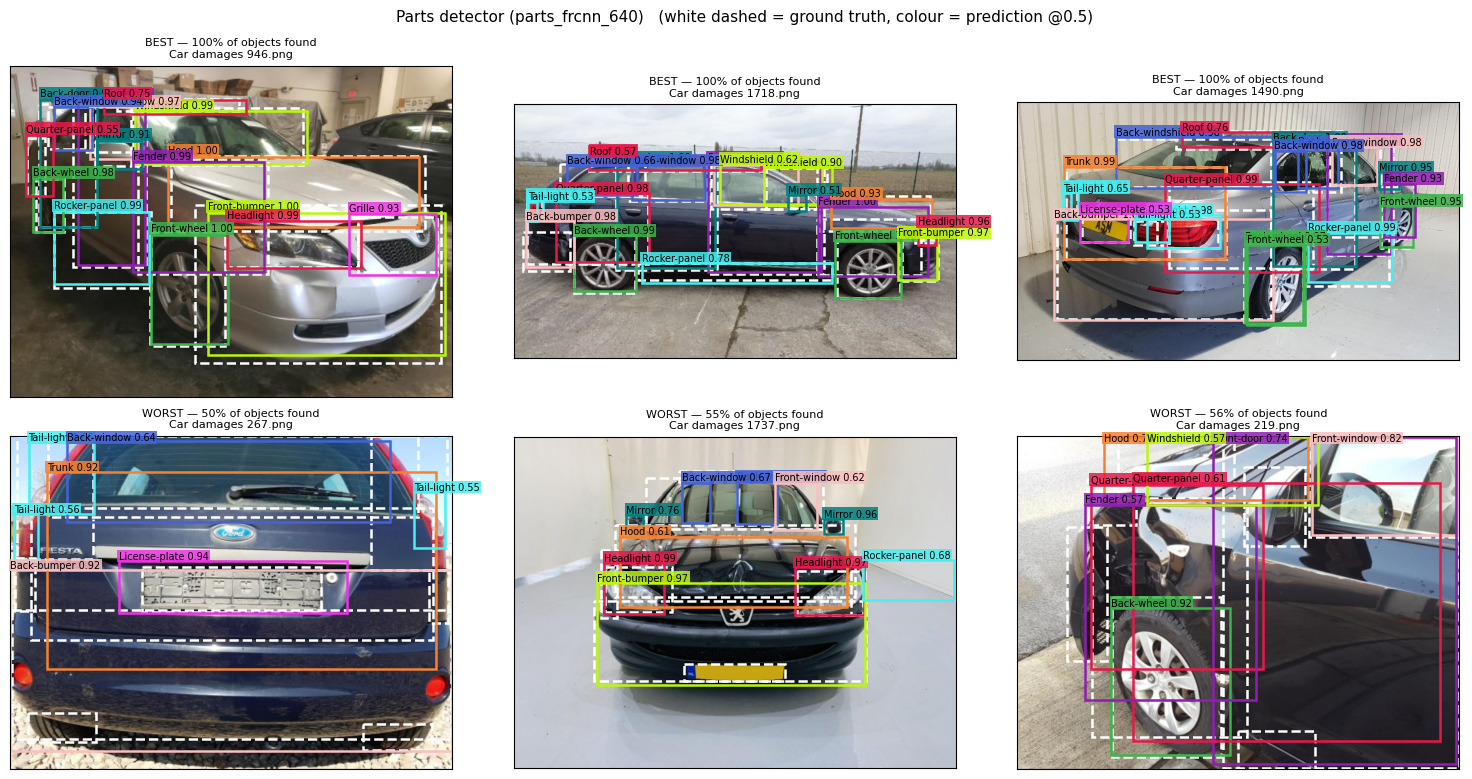

figures saved to /content/drive/MyDrive/motor-claim-runs/evaluation


In [ ]:
gallery(damage_paths, damage_gt, damage_pred, DAMAGE_CLASSES,
        f"Damage detector ({DAMAGE_RUN})", "damage_examples.png")
gallery(parts_paths, parts_gt, parts_pred, PARTS_CLASSES,
        f"Parts detector ({PARTS_RUN})", "parts_examples.png")
print("figures saved to", REPORT_DIR)

In [ ]:
COSMETIC = {"Scratch", "Paint chip", "Other damage"} 
SCORE_THRESHOLD = 0.6  


@torch.no_grad()
def assess(image_path, score_thr=SCORE_THRESHOLD, min_containment=0.5):
    """Both detectors on one photo, each damage assigned to the part containing most of
    it. Returns the dict the policy stage consumes, plus explicit review reasons.

    Still not scorable here: no image in this dataset carries both part and damage
    labels, so the linking step has no ground truth until the test claims are labelled.
    """
    with Image.open(image_path) as im:
        t = TF.to_tensor(im.convert("RGB")).to(DEVICE)
    dmg, prt = damage_model([t])[0], parts_model([t])[0]

    parts = [(PARTS_CLASSES[int(l) - 1], b.tolist(), float(s)) for b, l, s
             in zip(prt["boxes"], prt["labels"], prt["scores"]) if s >= score_thr]
    dmgs = [(DAMAGE_CLASSES[int(l) - 1], b.tolist(), float(s)) for b, l, s
            in zip(dmg["boxes"], dmg["labels"], dmg["scores"]) if s >= score_thr]

    found, unlinked, marginal = defaultdict(set), [], []
    for dname, dbox, dscore in dmgs:
        best, best_c = None, 0.0
        for pname, pbox, _ in parts:
            c = containment(dbox, pbox)
            if c >= min_containment and c > best_c:
                best, best_c = pname, c
        if best is None:
            unlinked.append(dname)
        else:
            found[best].add(dname)
            if best_c < 0.8:          
                marginal.append(f"{dname} on {best} ({best_c:.0%} inside)")

    kinds = {d for v in found.values() for d in v} | set(unlinked)
    reasons = []
    if not parts:
        reasons.append("no car parts found - the photo may not show a vehicle")
    if unlinked:
        reasons.append(f"damage not on any identified part: {', '.join(sorted(set(unlinked)))}")
    if not dmgs:
        reasons.append("no damage found - but the detector misses about 73% of damage "
                       "instances, so this is not proof the car is undamaged")
    if kinds and kinds <= COSMETIC:
        reasons.append("only cosmetic damage found (scratch / paint chip), which this "
                       "model detects poorly - the list is probably incomplete")
    if marginal:
        reasons.append("damage straddles a panel edge, so the part may be wrong: "
                       + "; ".join(marginal))

    return {"parts_detected": sorted({p[0] for p in parts}),
            "damaged_parts": {k: sorted(v) for k, v in sorted(found.items())},
            "damage_not_linked_to_a_part": sorted(set(unlinked)),
            "needs_manual_review": bool(reasons),
            "review_reasons": reasons,
            "score_threshold": score_thr}


for p in damage_paths[:5]:
    print(p.name)
    print(json.dumps(assess(p), indent=2), "\n")

Car damages 106.png
{
  "parts_detected": [
    "Fender",
    "Front-bumper",
    "Front-door",
    "Front-wheel",
    "Grille",
    "Headlight",
    "Hood",
    "Rocker-panel"
  ],
  "damaged_parts": {
    "Fender": [
      "Dent",
      "Scratch"
    ],
    "Grille": [
      "Broken part"
    ]
  },
  "damage_not_linked_to_a_part": [],
  "needs_manual_review": false,
  "review_reasons": [],
  "score_threshold": 0.6
} 

Car damages 1063.png
{
  "parts_detected": [
    "Back-door",
    "Back-wheel",
    "Back-window",
    "Fender",
    "Front-bumper",
    "Front-door",
    "Front-wheel",
    "Front-window",
    "Grille",
    "Headlight",
    "Hood",
    "Mirror",
    "Rocker-panel",
    "Roof",
    "Windshield"
  ],
  "damaged_parts": {
    "Fender": [
      "Dent"
    ],
    "Front-bumper": [
      "Dent",
      "Missing part",
      "Scratch"
    ],
    "Grille": [
      "Missing part"
    ]
  },
  "damage_not_linked_to_a_part": [],
  "needs_manual_review": false,
  "review_reasons":

In [ ]:
ROWS = ["parts_frcnn_640", "damage_maskrcnn_1024",
        "abl_mnv3_640", "abl_mnv3_1024", "abl_r50_640", "abl_r50_1024",
        "final_r50_640_40ep"]

print(f"{'run':24s}{'classes':>8}{'input':>7}{'epochs':>8}{'box mAP@50':>12}"
      f"{'box mAP':>9}{'seg mAP@50':>12}{'best ep':>9}")
summary = {}
for name in ROWS:
    f = Path(OUT) / name / "metrics.json"
    if not f.exists():
        print(f"{name:24s}{'not run':>57}")
        continue
    m = json.loads(f.read_text())
    t = m["test"]
    summary[name] = t
    print(f"{name:24s}{len(m['classes']):>8}{m['config']['min_sizes'][-1]:>7}"
          f"{m['config']['epochs']:>8}{t['box_map_50']:>12.3f}{t['box_map']:>9.3f}"
          f"{t.get('seg_map_50', float('nan')):>12.3f}{m['best_epoch'] + 1:>9}")

json.dump(summary, open(f"{OUT}/evaluation/all_runs.json", "w"), indent=1)
print(f"\nsaved -> {OUT}/evaluation/all_runs.json")
print("\nChosen: final_r50_640_40ep at threshold 0.6 - worst on mAP, best on the")
print("per-image metric the claim pipeline actually uses. See model_choice.json.")

run                      classes  input  epochs  box mAP@50  box mAP  seg mAP@50  best ep
parts_frcnn_640               21    640      20       0.836    0.539         nan       18
damage_maskrcnn_1024           6   1024      20       0.148    0.071       0.135        7
abl_mnv3_640                   6    640      20       0.079    0.033         nan       12
abl_mnv3_1024                  6   1024      20       0.104    0.043         nan       18
abl_r50_640                    6    640      20       0.133    0.063         nan       20
abl_r50_1024                   6   1024      20       0.150    0.073         nan        9
final_r50_640_40ep             6    640      40       0.130    0.058         nan       13

saved -> /content/drive/MyDrive/motor-claim-runs/evaluation/all_runs.json

Chosen: final_r50_640_40ep at threshold 0.6 - worst on mAP, best on the
per-image metric the claim pipeline actually uses. See model_choice.json.
